# Bài thực hành 7: Đánh giá mô hình

**Sinh viên:** Nguyễn Thành Phong · **Học phần:** Học máy ứng dụng · **Giảng viên:** ThS. Nguyễn Thái Anh

Dữ liệu (số liệu mô phỏng dùng cho giảng dạy):
- `data/sinh_vien_bo_hoc.csv`: 1200 sinh viên, 5 cột `diem_tb` (thang 10), `so_buoi_vang`, `tin_chi_no`, `gio_lam_them` (giờ/tuần), `bo_hoc` (nhãn, 1 = bỏ học). Chỉ khoảng 10% bỏ học.
- `data/gia_nha.csv`: dùng lại từ bài 1, 60 căn nhà (bài tập 6).
- Bài tập 2 dùng bộ chữ số viết tay `load_digits` có sẵn trong scikit-learn.

> **Lưu ý về dữ liệu.** Đề không phát kèm `sinh_vien_bo_hoc.csv` và không cho mã sinh dữ liệu, nên tệp được dựng lại bằng `data/tao_du_lieu.py` theo mô tả của đề: 1200 dòng, đúng 119 bạn bỏ học, năm dòng đầu giống hệt bảng `df.head()` trong đề, và hạt giống được chọn để ma trận nhầm lẫn của hồi quy logistic khớp đề (TN 267, FP 3, FN 13, TP 17). Vì vậy mục 2, 3, 4 khớp đề từng con số; các mục sau chỉ gần đúng, và mỗi chỗ lệch được ghi trong phần nhận xét.

Mỗi mục bên dưới ứng với một tệp trong `code/` (phần bài giảng) hoặc `baitap07/` (phần bài tập).
Chạy các tệp đó từ thư mục `Lab07/`, ví dụ `python baitap07/bai1.py`.

In [1]:
# Chuẩn bị dữ liệu: chạy local thì đọc thẳng, trên Colab thì tải hai tệp lên
import os
CAN_CO = ["data/sinh_vien_bo_hoc.csv", "data/gia_nha.csv"]
if not all(os.path.exists(p) for p in CAN_CO):
    from google.colab import files
    files.upload()                         # chon ca sinh_vien_bo_hoc.csv va gia_nha.csv
    os.makedirs("data", exist_ok=True)
    for p in CAN_CO:
        if os.path.exists(os.path.basename(p)):
            os.replace(os.path.basename(p), p)
for p in CAN_CO:
    print(f"Co {p} chua?", os.path.exists(p))

Co data/sinh_vien_bo_hoc.csv chua? True
Co data/gia_nha.csv chua? True


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (confusion_matrix, f1_score, precision_score,
                             recall_score, roc_curve)

# Hai màu cố định cho hai lớp, dùng chung cho mọi hình
MAU_BO = "#eb6834"         # bỏ học (lớp 1)
MAU_KHONG = "#2a78d6"      # học tiếp (lớp 0)
MAU_F1 = "#1f7a3a"
MAU_CHU = "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MAU_CHU, "axes.grid": True, "grid.color": "#e4e3df",
    "grid.linewidth": 0.8, "axes.axisbelow": True, "lines.linewidth": 2,
})


def ve_ma_tran(ax, m, tieu_de):
    """Ve ma tran nham lan 2 x 2, hang la nhan that, cot la nhan doan."""
    ax.imshow(m, cmap="Blues", vmin=0, vmax=m.sum())
    for i in range(2):
        for j in range(2):
            ax.text(j, i, m[i, j], ha="center", va="center", fontsize=14,
                    color="white" if m[i, j] > m.sum() / 2 else "black")
    ax.set_xticks([0, 1], ["Không bỏ", "Bỏ học"]); ax.set_yticks([0, 1], ["Không bỏ", "Bỏ học"])
    ax.set_xlabel("Mô hình đoán"); ax.set_ylabel("Thực tế"); ax.set_title(tieu_de); ax.grid(False)

## 1. Khi accuracy đánh lừa (`code/h1_do_bua.py`)

In [3]:
import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("data/sinh_vien_bo_hoc.csv")
print("Kich thuoc bang:", df.shape)
print(df.head())
print()
print("So sinh vien moi lop:")
print(df["bo_hoc"].value_counts().to_string())
print(f"Ty le bo hoc: {df['bo_hoc'].mean():.3f}")
print()

X = df.drop(columns="bo_hoc")
y = df["bo_hoc"]
# stratify=y giữ đúng tỷ lệ bỏ học ở cả tập học lẫn tập kiểm tra
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)
print(f"Tap kiem tra: {len(y_te)} ban, {y_te.sum()} ban bo hoc")
print()

# Mô hình lười: ai cũng đoán là lớp đông nhất
luoi = DummyClassifier(strategy="most_frequent").fit(X_tr, y_tr)
du_luoi = luoi.predict(X_te)

lr = make_pipeline(StandardScaler(), LogisticRegression())
lr.fit(X_tr, y_tr)
du_lr = lr.predict(X_te)

for ten, du in [("Mo hinh luoi", du_luoi), ("Hoi quy logistic", du_lr)]:
    acc = accuracy_score(y_te, du)
    tim_ra = ((du == 1) & (y_te == 1)).sum()
    print(f"{ten:17s} accuracy {acc:.4f}, "
          f"tim ra {tim_ra} tren {y_te.sum()} ban bo hoc")

Kich thuoc bang: (1200, 5)
   diem_tb  so_buoi_vang  tin_chi_no  gio_lam_them  bo_hoc
0      8.0             3           0             0       0
1      8.9             5           1             7       0
2      3.3             3           1             4       0
3      6.4             3           0             7       0
4      7.9             3           5            23       0

So sinh vien moi lop:
bo_hoc
0    1081
1     119
Ty le bo hoc: 0.099

Tap kiem tra: 300 ban, 30 ban bo hoc

Mo hinh luoi      accuracy 0.9000, tim ra 0 tren 30 ban bo hoc
Hoi quy logistic  accuracy 0.9467, tim ra 17 tren 30 ban bo hoc


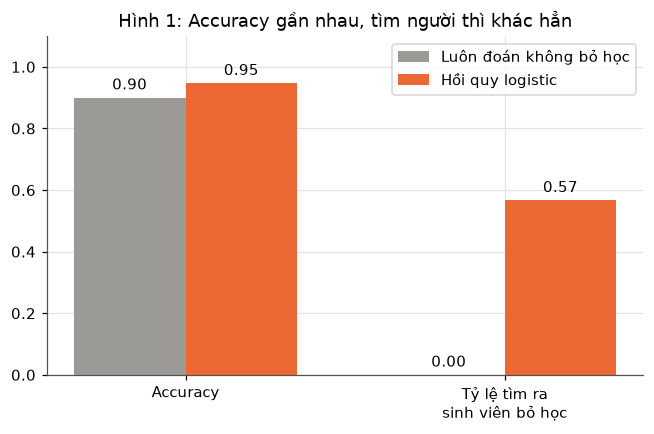

In [4]:
# Hình 1: accuracy và tỷ lệ tìm ra sinh viên bỏ học của hai mô hình
ten_mh = ["Luôn đoán không bỏ học", "Hồi quy logistic"]
acc = [accuracy_score(y_te, du_luoi), accuracy_score(y_te, du_lr)]
tim = [recall_score(y_te, du_luoi, zero_division=0), recall_score(y_te, du_lr)]
fig, ax = plt.subplots(figsize=(7, 4))
vt = np.arange(2)
for k, (gt, mau) in enumerate(zip(zip(acc, tim), ["#9b9a96", MAU_BO])):
    cot = ax.bar(vt + (k - 0.5) * 0.35, gt, 0.35, color=mau, label=ten_mh[k])
    ax.bar_label(cot, fmt="%.2f", padding=3)
ax.set_xticks(vt, ["Accuracy", "Tỷ lệ tìm ra\nsinh viên bỏ học"]); ax.set_ylim(0, 1.1)
ax.set_title("Hình 1: Accuracy gần nhau, tìm người thì khác hẳn"); ax.legend(loc="upper right"); plt.show()

**Nhận xét.** Khớp tài liệu từng con số. Bảng có 1200 dòng, năm dòng đầu giống bảng trong đề, và chỉ **119 trên 1200** sinh viên bỏ học (tỷ lệ 0.099). Nhờ `stratify=y`, tập kiểm tra có đúng 30 trên 300 bạn bỏ học (119 × 0.25 ≈ 29.75 làm tròn thành 30), giữ nguyên tỷ lệ đó.

Mô hình lười (`DummyClassifier(strategy="most_frequent")`) đạt accuracy **0.9000** mà **không tìm ra một bạn bỏ học nào**: nó chỉ đoán "không bỏ" cho cả 300 bạn và đúng 270 lần. Hồi quy logistic đạt **0.9467**, hơn mô hình lười chưa tới 5 điểm phần trăm, nhưng tìm ra **17 trên 30** bạn (Hình 1). Hai mô hình gần nhau về accuracy nhưng khác hẳn nhau về đúng điều nhà trường cần.

Với dữ liệu lệch lớp, accuracy của mô hình lười bằng đúng tỷ lệ lớp đông nhất (0.90), nên đó là **mức sàn**, không phải 0. Mọi mô hình phải được so với mức sàn này trước, rồi mới nhìn tới các thước đo riêng cho lớp hiếm ở các mục sau.

## 2. Ma trận nhầm lẫn (`code/h2_ma_tran.py`)

| | Đoán không bỏ học (0) | Đoán bỏ học (1) |
|---|---|---|
| **Thật không bỏ (0)** | TN, đoán đúng lớp 0 | FP, báo động nhầm |
| **Thật bỏ học (1)** | FN, bỏ sót | TP, đoán đúng lớp 1 |

In [5]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("data/sinh_vien_bo_hoc.csv")
X = df.drop(columns="bo_hoc")
y = df["bo_hoc"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

lr = make_pipeline(StandardScaler(), LogisticRegression())
du = lr.fit(X_tr, y_tr).predict(X_te)
that = y_te.to_numpy()

# Tự đếm: mỗi ô là một cặp (nhãn thật, nhãn đoán)
tp = np.sum((that == 1) & (du == 1))
fp = np.sum((that == 0) & (du == 1))
fn = np.sum((that == 1) & (du == 0))
tn = np.sum((that == 0) & (du == 0))
print("Tu dem:")
print(f"  TP = {tp}  (doan bo hoc, dung la bo hoc)")
print(f"  FP = {fp}  (bao dong nham)")
print(f"  FN = {fn}  (bo sot)")
print(f"  TN = {tn}  (doan khong bo, dung la khong bo)")
print(f"  Tong = {tp + fp + fn + tn}")
print()

m = confusion_matrix(that, du)
print("confusion_matrix cua scikit-learn:")
print(m)
print("Thu tu khi trai ra: TN, FP, FN, TP =", m.ravel())
print()

acc = (tp + tn) / (tp + fp + fn + tn)
print(f"Accuracy tinh tu bon o: ({tp} + {tn}) / {len(that)} = {acc:.4f}")
print(f"So ban bi bao co nguy co: TP + FP = {tp + fp}")

Tu dem:
  TP = 17  (doan bo hoc, dung la bo hoc)
  FP = 3  (bao dong nham)
  FN = 13  (bo sot)
  TN = 267  (doan khong bo, dung la khong bo)
  Tong = 300

confusion_matrix cua scikit-learn:
[[267   3]
 [ 13  17]]
Thu tu khi trai ra: TN, FP, FN, TP = [267   3  13  17]

Accuracy tinh tu bon o: (17 + 267) / 300 = 0.9467
So ban bi bao co nguy co: TP + FP = 20


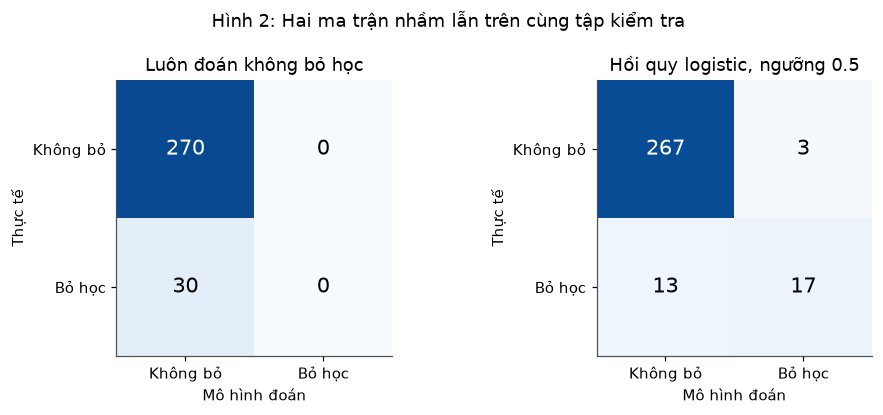

In [6]:
# Hình 2: ma trận nhầm lẫn của mô hình lười và của hồi quy logistic
fig, axs = plt.subplots(1, 2, figsize=(9, 3.8))
ve_ma_tran(axs[0], confusion_matrix(that, np.zeros_like(that)), "Luôn đoán không bỏ học")
ve_ma_tran(axs[1], m, "Hồi quy logistic, ngưỡng 0.5")
fig.suptitle("Hình 2: Hai ma trận nhầm lẫn trên cùng tập kiểm tra"); plt.tight_layout(); plt.show()

**Nhận xét.** Khớp tài liệu. Bốn ô tự đếm bằng numpy trùng với `confusion_matrix`: **TN = 267, FP = 3, FN = 13, TP = 17**, tổng 300. Accuracy tính từ bốn ô là (17 + 267) / 300 = 0.9467, đúng như mục 1.

Hình 2 đặt hai ma trận cạnh nhau. Ma trận của mô hình lười có cả cột "Bỏ học" bằng 0: nó dồn hết 30 bạn bỏ học vào ô FN. Logistic báo **20 bạn** có nguy cơ (TP + FP), trong đó 17 bạn bỏ học thật và chỉ 3 bạn báo nhầm, nhưng vẫn **bỏ sót 13 bạn**, gần một nửa số bạn bỏ học.

Ma trận của scikit-learn đặt **hàng là nhãn thật, cột là nhãn đoán**, lớp 0 trước. Vì vậy `m.ravel()` trả về theo thứ tự **TN, FP, FN, TP** (in ra `[267 3 13 17]`). Viết `tp, fp, fn, tn = m.ravel()` là lỗi hay gặp: TP sẽ thành 267 và mọi con số sau đó sai theo.

## 3. Precision, recall và F1 (`code/h3_precision_recall.py`)

$$\text{Precision} = \frac{TP}{TP+FP} \qquad \text{Recall} = \frac{TP}{TP+FN} \qquad F_1 = \frac{2 \times \text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$$

In [7]:
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, confusion_matrix,
                             f1_score, precision_score, recall_score)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("data/sinh_vien_bo_hoc.csv")
X = df.drop(columns="bo_hoc")
y = df["bo_hoc"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

lr = make_pipeline(StandardScaler(), LogisticRegression())
du = lr.fit(X_tr, y_tr).predict(X_te)
tn, fp, fn, tp = confusion_matrix(y_te, du).ravel()

p = tp / (tp + fp)
r = tp / (tp + fn)
f1 = 2 * p * r / (p + r)
print("Tinh tay tu bon o:")
print(f"  Precision = {tp} / ({tp} + {fp}) = {p:.4f}")
print(f"  Recall    = {tp} / ({tp} + {fn}) = {r:.4f}")
print(f"  F1        = 2 x {p:.4f} x {r:.4f} / ({p:.4f} + {r:.4f})"
      f" = {f1:.4f}")
print()

print("Tinh bang scikit-learn:")
print(f"  Precision = {precision_score(y_te, du):.4f}")
print(f"  Recall    = {recall_score(y_te, du):.4f}")
print(f"  F1        = {f1_score(y_te, du):.4f}")
print()

print("Bao cao day du:")
print(classification_report(y_te, du, digits=4,
                            target_names=["khong bo", "bo hoc"]))

Tinh tay tu bon o:
  Precision = 17 / (17 + 3) = 0.8500
  Recall    = 17 / (17 + 13) = 0.5667
  F1        = 2 x 0.8500 x 0.5667 / (0.8500 + 0.5667) = 0.6800

Tinh bang scikit-learn:
  Precision = 0.8500
  Recall    = 0.5667
  F1        = 0.6800

Bao cao day du:
              precision    recall  f1-score   support

    khong bo     0.9536    0.9889    0.9709       270
      bo hoc     0.8500    0.5667    0.6800        30

    accuracy                         0.9467       300
   macro avg     0.9018    0.7778    0.8255       300
weighted avg     0.9432    0.9467    0.9418       300



**Nhận xét.** Khớp tài liệu. Tính tay từ bốn ô và tính bằng thư viện ra cùng ba con số: **precision 0.8500, recall 0.5667, F1 0.6800**. Nghĩa là cứ 20 lời báo động thì 17 lời đúng, nhưng mô hình chỉ tìm ra 17 trên 30 bạn bỏ học. F1 là trung bình điều hoà nên bị kéo về phía con số nhỏ hơn: 0.68 gần recall 0.57 hơn là trung bình cộng 0.71.

Đọc `classification_report` (trùng tài liệu tới chữ số thứ tư):
- Dòng `khong bo` có recall 0.9889 (267/270), vì gần như bạn học tiếp nào cũng được đoán đúng. Dòng này đẹp nhưng không phải điều cần hỏi.
- Dòng `bo hoc` mới là dòng cần đọc trước: recall chỉ **0.5667**.
- `support` là số mẫu thật của mỗi lớp, 270 và 30.
- `macro avg` lấy trung bình cộng hai lớp, mỗi lớp nặng như nhau, nên F1 macro chỉ 0.8255. `weighted avg` lấy trung bình theo số mẫu, bị lớp đông (270 bạn) chi phối nên F1 lên 0.9418, gần accuracy. Với dữ liệu lệch lớp, nên nhìn macro avg hoặc nhìn thẳng dòng lớp hiếm.

Ở bài này bỏ sót một bạn sắp bỏ học đắt hơn nhiều so với một buổi tư vấn thừa, nên **ưu tiên recall**; mục 4 cho thấy cách đẩy recall lên.

## 4. Đổi ngưỡng quyết định (`code/h4_nguong.py`)

In [8]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, precision_score, recall_score
from sklearn.model_selection import cross_val_predict, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("data/sinh_vien_bo_hoc.csv")
X = df.drop(columns="bo_hoc")
y = df["bo_hoc"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

lr = make_pipeline(StandardScaler(), LogisticRegression())
lr.fit(X_tr, y_tr)
xs = lr.predict_proba(X_te)[:, 1]     # xác suất bỏ học của từng bạn

print("Tap kiem tra, doi nguong")
print("nguong  so bao   TP  FP  FN   precision  recall   F1")
for t in [0.5, 0.4, 0.3, 0.2, 0.1]:
    du = (xs >= t).astype(int)
    tp = int(((du == 1) & (y_te == 1)).sum())
    fp = int(((du == 1) & (y_te == 0)).sum())
    fn = int(((du == 0) & (y_te == 1)).sum())
    print(f"  {t:.1f}    {du.sum():4d}   {tp:3d} {fp:3d} {fn:3d}"
          f"    {precision_score(y_te, du):.4f}    "
          f"{recall_score(y_te, du):.4f}  {f1_score(y_te, du):.4f}")
print()

# Chọn ngưỡng đúng cách: chỉ dùng tập học, qua kiểm định chéo.
# Mỗi bạn trong tập học nhận xác suất từ một mô hình chưa từng thấy bạn ấy.
xs_hoc = cross_val_predict(lr, X_tr, y_tr, cv=5,
                           method="predict_proba")[:, 1]
cac_nguong = np.round(np.arange(0.05, 0.96, 0.05), 2)
f1_hoc = [f1_score(y_tr, (xs_hoc >= t).astype(int)) for t in cac_nguong]
t_tot = cac_nguong[int(np.argmax(f1_hoc))]
print(f"Nguong cho F1 cao nhat tren tap hoc: {t_tot}"
      f" (F1 kiem dinh cheo {max(f1_hoc):.4f})")

# Chọn xong mới dùng tập kiểm tra, và chỉ một lần
du = (xs >= t_tot).astype(int)
print(f"Tap kiem tra voi nguong {t_tot}:"
      f" precision {precision_score(y_te, du):.4f},"
      f" recall {recall_score(y_te, du):.4f},"
      f" F1 {f1_score(y_te, du):.4f}")

Tap kiem tra, doi nguong
nguong  so bao   TP  FP  FN   precision  recall   F1
  0.5      20    17   3  13    0.8500    0.5667  0.6800
  0.4      25    19   6  11    0.7600    0.6333  0.6909
  0.3      30    20  10  10    0.6667    0.6667  0.6667
  0.2      41    22  19   8    0.5366    0.7333  0.6197
  0.1      56    26  30   4    0.4643    0.8667  0.6047



Nguong cho F1 cao nhat tren tap hoc: 0.25 (F1 kiem dinh cheo 0.6373)
Tap kiem tra voi nguong 0.25: precision 0.6452, recall 0.6667, F1 0.6557


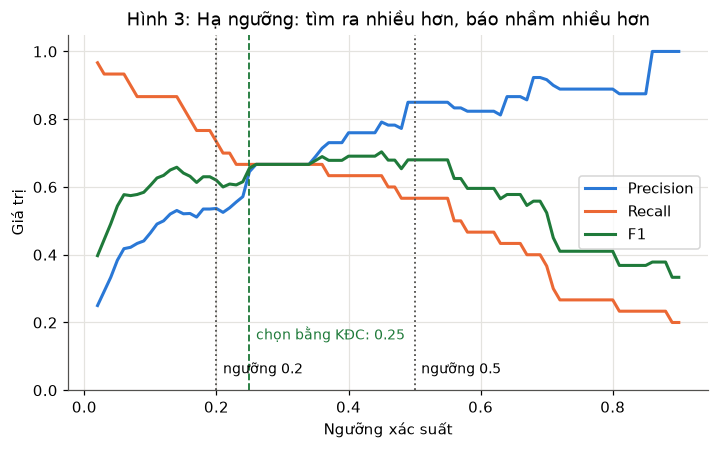

In [9]:
# Hình 3: precision, recall và F1 trên tập kiểm tra theo ngưỡng xác suất
cac_t = np.round(np.arange(0.02, 0.91, 0.01), 2)
bang_t = {"Precision": [], "Recall": [], "F1": []}
for t in cac_t:
    d = (xs >= t).astype(int)
    bang_t["Precision"].append(precision_score(y_te, d, zero_division=0))
    bang_t["Recall"].append(recall_score(y_te, d))
    bang_t["F1"].append(f1_score(y_te, d))
fig, ax = plt.subplots(figsize=(7.5, 4.2))
for (ten, gt), mau in zip(bang_t.items(), [MAU_KHONG, MAU_BO, MAU_F1]):
    ax.plot(cac_t, gt, color=mau, label=ten)
for t in [0.2, 0.5]:
    ax.axvline(t, ls=":", color=MAU_CHU, lw=1.2); ax.text(t + 0.01, 0.05, f"ngưỡng {t}", fontsize=9)
ax.axvline(t_tot, ls="--", color=MAU_F1, lw=1.2); ax.text(t_tot + 0.01, 0.15, f"chọn bằng KĐC: {t_tot}", fontsize=9, color=MAU_F1)
ax.set_xlabel("Ngưỡng xác suất"); ax.set_ylabel("Giá trị"); ax.set_ylim(0, 1.05)
ax.set_title("Hình 3: Hạ ngưỡng: tìm ra nhiều hơn, báo nhầm nhiều hơn"); ax.legend(loc="center right"); plt.show()

**Nhận xét.** Dòng ngưỡng 0.5 khớp tài liệu (20 lời báo, 17 / 3 / 13). Các dòng còn lại khác tài liệu vì dữ liệu được dựng lại, xu hướng thì giống hệt. Hạ ngưỡng từ 0.5 xuống 0.1:
- số bạn bị báo tăng từ **20 lên 56** (đề: 61);
- số bạn bỏ sót giảm từ 13 xuống **4**, recall tăng từ 0.5667 lên **0.8667** (trùng đề);
- số báo động nhầm tăng từ 3 lên **30** (đề: 35), precision giảm từ 0.8500 xuống **0.4643** (đề: 0.4262).

Hình 3 cho thấy recall đi lên, precision đi xuống khi hạ ngưỡng, không có ngưỡng nào làm cả hai cùng cao nhất. Chọn ngưỡng là chọn một điểm đánh đổi.

**Chọn ngưỡng đúng cách.** `cross_val_predict` cho mỗi bạn trong tập học một xác suất đến từ mô hình chưa thấy bạn ấy; trên các xác suất đó, ngưỡng cho F1 cao nhất là **0.25**, trùng tài liệu (F1 kiểm định chéo 0.6373, đề 0.6473). Mở tập kiểm tra một lần: precision 0.6452, recall 0.6667, F1 **0.6557** (đề: 0.6571, 0.7667, 0.7077). Lệch lớn nhất ở recall: 20 thay vì 23 trên 30 bạn, tức chênh 3 bạn, một khác biệt rất dễ xảy ra khi lớp dương chỉ có 30 mẫu (mỗi bạn là 0.033 recall).

Nếu nhìn bảng thứ nhất để chọn thì ngưỡng 0.4 cho F1 cao nhất trên tập kiểm tra (0.6909), cao hơn 0.6557. Trên dữ liệu này, ngưỡng chọn trung thực thậm chí còn thua ngưỡng mặc định 0.5 (F1 0.6800) trên tập kiểm tra. Đó **không** phải lý do để quay lại chọn theo tập kiểm tra: con số 0.6909 đẹp hơn chỉ vì ngưỡng được chọn sau khi đã nhìn đáp án. Nó cho thấy với 30 bạn bỏ học, F1 trên tập kiểm tra dao động mạnh, và ngay trên tập học, F1 kiểm định chéo khá phẳng từ ngưỡng 0.20 tới 0.45 (0.616 tới 0.637), nên chênh lệch giữa các ngưỡng gần nhau phần lớn là nhiễu.

## 5. Đường ROC và AUC (`code/h5_roc_auc.py`)

$$\text{tỷ lệ báo động nhầm} = \frac{FP}{FP+TN} \qquad \text{recall} = \frac{TP}{TP+FN}$$

In [10]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, recall_score, roc_auc_score
from sklearn.metrics import roc_curve
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

df = pd.read_csv("data/sinh_vien_bo_hoc.csv")
X = df.drop(columns="bo_hoc")
y = df["bo_hoc"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

lr = make_pipeline(StandardScaler(), LogisticRegression())
xs = lr.fit(X_tr, y_tr).predict_proba(X_te)[:, 1]

# Mỗi ngưỡng cho một điểm của đường ROC
fpr, tpr, nguong = roc_curve(y_te, xs)
print("Duong ROC co", len(fpr), "diem. Vai diem dau:")
print("  bao dong nham   recall")
for a, b in list(zip(fpr, tpr))[:6]:
    print(f"      {a:.4f}      {b:.4f}")
print(f"AUC cua logistic = {roc_auc_score(y_te, xs):.4f}")
print()

# So các mô hình đã học, cùng tập học, cùng tập kiểm tra
mo_hinh = {
    "Logistic": lr,
    "Naive Bayes": GaussianNB(),
    "KNN, k = 15": make_pipeline(StandardScaler(),
                                 KNeighborsClassifier(15)),
    "Cay sau 4": DecisionTreeClassifier(max_depth=4, random_state=0),
    "Rung 200 cay": RandomForestClassifier(200, random_state=0),
    "SVM RBF": make_pipeline(StandardScaler(),
                             SVC(probability=True, random_state=0)),
}
print("Mo hinh          AUC     recall   F1   (nguong 0.5)")
for ten, mh in mo_hinh.items():
    mh.fit(X_tr, y_tr)
    p = mh.predict_proba(X_te)[:, 1]
    du = (p >= 0.5).astype(int)
    print(f"  {ten:14s} {roc_auc_score(y_te, p):.4f}   "
          f"{recall_score(y_te, du):.4f}  {f1_score(y_te, du):.4f}")

Duong ROC co 36 diem. Vai diem dau:
  bao dong nham   recall
      0.0000      0.0000
      0.0000      0.0333
      0.0000      0.2333
      0.0037      0.2333
      0.0037      0.4000
      0.0074      0.4000
AUC cua logistic = 0.9491

Mo hinh          AUC     recall   F1   (nguong 0.5)
  Logistic       0.9491   0.5667  0.6800
  Naive Bayes    0.9448   0.6333  0.6552
  KNN, k = 15    0.9256   0.2667  0.3902
  Cay sau 4      0.9026   0.4333  0.5778


  Rung 200 cay   0.9372   0.5667  0.6296
  SVM RBF        0.8558   0.5000  0.6250


/home/coder/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


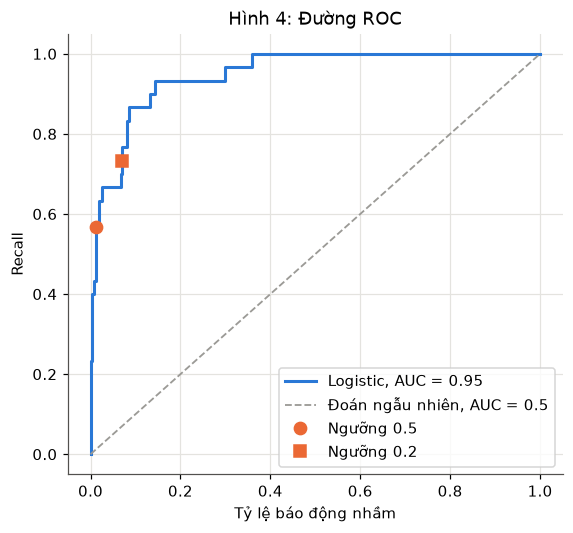

In [11]:
# Hình 4: đường ROC của hồi quy logistic, đánh dấu ngưỡng 0.5 và ngưỡng 0.2
fig, ax = plt.subplots(figsize=(5.8, 5.2))
auc_lr = roc_auc_score(y_te, xs)
ax.plot(fpr, tpr, color=MAU_KHONG, label=f"Logistic, AUC = {auc_lr:.2f}")
ax.plot([0, 1], [0, 1], "--", color="#9b9a96", lw=1.2, label="Đoán ngẫu nhiên, AUC = 0.5")
for t, mk in [(0.5, "o"), (0.2, "s")]:
    d = (xs >= t).astype(int)
    tn_, fp_, fn_, tp_ = confusion_matrix(y_te, d).ravel()
    ax.plot(fp_ / (fp_ + tn_), tp_ / (tp_ + fn_), mk, color=MAU_BO, ms=8, label=f"Ngưỡng {t}")
ax.set_xlabel("Tỷ lệ báo động nhầm"); ax.set_ylabel("Recall")
ax.set_title("Hình 4: Đường ROC"); ax.legend(loc="lower right"); plt.show()

**Nhận xét.** Đường ROC của logistic có **36 điểm** (đề: 28) và AUC **0.9491** (đề: 0.9449). Hai con số này phụ thuộc vào từng giá trị xác suất của 300 bạn nên khác đề do dữ liệu dựng lại, nhưng hình dạng giống: ngay ở đầu đường, recall đã lên 0.4000 mà tỷ lệ báo động nhầm mới 0.0037 (1 bạn trên 270), tức những bạn có xác suất cao nhất gần như đều bỏ học thật. Hình 4 đánh dấu ngưỡng 0.5 (báo nhầm 0.011, recall 0.567) và ngưỡng 0.2 (báo nhầm 0.070, recall 0.733): đổi ngưỡng chỉ là trượt dọc trên cùng một đường, còn AUC đo cả đường nên **không phụ thuộc ngưỡng**.

AUC hiểu bằng lời: bốc ngẫu nhiên một bạn bỏ học và một bạn không bỏ, xác suất mô hình cho bạn bỏ học điểm nguy cơ cao hơn là khoảng 0.95.

So sáu mô hình (đề trong ngoặc):

| Mô hình | AUC | Recall (0.5) | F1 (0.5) |
|---|---|---|---|
| Logistic | **0.9491** (0.9449) | 0.5667 (0.5667) | **0.6800** (0.6800) |
| Naive Bayes | 0.9448 (0.9336) | 0.6333 (0.3667) | 0.6552 (0.5116) |
| KNN, k = 15 | 0.9256 (0.9274) | 0.2667 (0.2333) | 0.3902 (0.3684) |
| Cây sâu 4 | 0.9026 (0.8803) | 0.4333 (0.4667) | 0.5778 (0.5957) |
| Rừng 200 cây | 0.9372 (0.9249) | 0.5667 (0.5667) | 0.6296 (0.6538) |
| SVM RBF | 0.8558 (0.8996) | 0.5000 (0.5000) | 0.6250 (0.6250) |

Kết luận chính giống đề: **hồi quy logistic có AUC cao nhất và F1 cao nhất** ở ngưỡng 0.5; rừng có cùng recall 0.5667 nhưng F1 thấp hơn; KNN có AUC khá (0.93) nhưng ở ngưỡng 0.5 recall chỉ 0.2667, vì với k = 15 láng giềng, một bạn phải có ít nhất 8 láng giềng bỏ học mới được báo, điều hiếm khi xảy ra với lớp chỉ 10%. KNN xếp hạng đúng nhưng báo quá ít, nên chọn lại ngưỡng là bắt buộc.

Lệch đáng kể nhất là Naive Bayes (recall 0.6333 so với 0.3667 của đề). Naive Bayes giả định các cột độc lập và có phân phối chuẩn trong mỗi lớp; trên dữ liệu dựng lại, điểm, số buổi vắng và tín chỉ nợ được sinh khác cách của tác giả, nên xác suất Naive Bayes đưa ra lệch về phía khác. Đây là mô hình nhạy nhất với hình dạng phân phối, nên lệch nhiều nhất là hợp lý. Ngoài ra scikit-learn 1.9 in `FutureWarning` vì `SVC(probability=True)` sắp bị bỏ (gợi ý dùng `CalibratedClassifierCV`); mã vẫn chạy đúng như đề.

Các cột ở đây quan hệ gần thẳng với nguy cơ bỏ học (trên thang logit), nên mô hình đơn giản nhất lại hợp nhất.

## 6. Kiểm định chéo nhiều thước đo và cân bằng lớp (`code/h6_can_bang.py`)

In [12]:
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, precision_score, recall_score
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("data/sinh_vien_bo_hoc.csv")
X = df.drop(columns="bo_hoc")
y = df["bo_hoc"]

# Chia không phân tầng: số bạn bỏ học trong tập kiểm tra dao động
print("Khong stratify, so ban bo hoc trong tap kiem tra:")
dem = []
for rs in range(10):
    _, _, _, y_te_thu = train_test_split(X, y, test_size=0.25,
                                         random_state=rs)
    dem.append(int(y_te_thu.sum()))
print(" ", dem)
print()

X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

lr = make_pipeline(StandardScaler(), LogisticRegression())
print("Kiem dinh cheo 5 phan tren tap hoc:")
for tm in ["accuracy", "precision", "recall", "f1"]:
    d = cross_val_score(lr, X_tr, y_tr, cv=5, scoring=tm)
    print(f"  {tm:10s} {d.mean():.4f}")
print()

# Cân bằng lớp: phạt nặng hơn khi đoán sai lớp hiếm
cb = make_pipeline(StandardScaler(),
                   LogisticRegression(class_weight="balanced"))
print("Tap kiem tra   precision  recall   F1")
for ten, mh in [("Binh thuong", lr), ("Can bang lop", cb)]:
    du = mh.fit(X_tr, y_tr).predict(X_te)
    print(f"  {ten:12s} {precision_score(y_te, du):.4f}    "
          f"{recall_score(y_te, du):.4f}  {f1_score(y_te, du):.4f}")

Khong stratify, so ban bo hoc trong tap kiem tra:
  [30, 18, 28, 35, 36, 32, 31, 30, 40, 28]

Kiem dinh cheo 5 phan tren tap hoc:
  accuracy   0.9311


  precision  0.7262
  recall     0.4843
  f1         0.5762

Tap kiem tra   precision  recall   F1
  Binh thuong  0.8500    0.5667  0.6800


  Can bang lop 0.4727    0.8667  0.6118


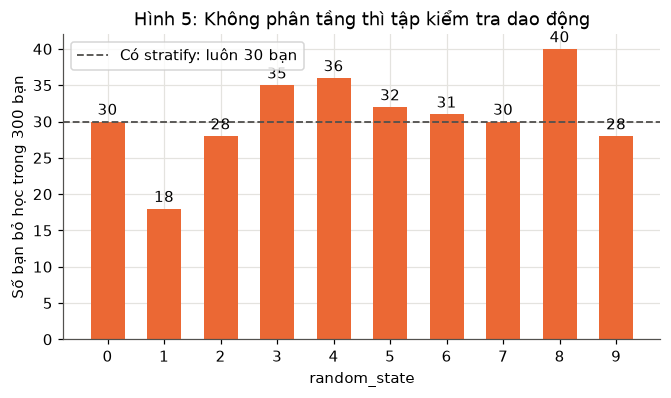

In [13]:
# Hình 5: số bạn bỏ học trong tập kiểm tra khi chia không phân tầng, mười cách chia
fig, ax = plt.subplots(figsize=(7, 3.6))
cot = ax.bar(range(10), dem, color=MAU_BO, width=0.6)
ax.bar_label(cot, padding=2)
ax.axhline(30, ls="--", color=MAU_CHU, lw=1.2, label="Có stratify: luôn 30 bạn")
ax.set_xticks(range(10)); ax.set_xlabel("random_state"); ax.set_ylabel("Số bạn bỏ học trong 300 bạn")
ax.set_title("Hình 5: Không phân tầng thì tập kiểm tra dao động"); ax.legend(loc="upper left"); plt.show()

**Nhận xét.** **Phân tầng.** Không có `stratify`, mười cách chia cho tập kiểm tra có từ **18 tới 40** bạn bỏ học (đề: 20 tới 35; dãy cụ thể phụ thuộc vào vị trí từng bạn bỏ học trong tệp nên không thể khớp đề với dữ liệu dựng lại). Hình 5 cho thấy tập kiểm tra có lúc chỉ 18 bạn, có lúc 40 bạn: recall tính trên 18 bạn thì mỗi bạn bằng 0.056, trên 40 bạn chỉ 0.025, nên kết quả giữa các lần chia khó so. Với `stratify=y`, tập kiểm tra luôn có đúng 30 bạn.

**Kiểm định chéo nhiều thước đo** (đề trong ngoặc): accuracy **0.9311** (0.9289), precision 0.7262 (0.7044), recall **0.4843** (0.4810), F1 0.5762 (0.5652). Accuracy 0.93 nghe rất cao, nhưng recall trung bình chưa tới 0.5: mô hình để sót hơn một nửa số bạn bỏ học. Tham số `scoring` dùng y hệt trong `GridSearchCV` để dò tham số theo recall hay F1.

**Cân bằng lớp.** `class_weight="balanced"` nhân trọng số của mỗi bạn bỏ học lên khoảng 1081/119 ≈ 9 lần so với bạn học tiếp khi tính hàm mất mát. Trên tập kiểm tra recall tăng từ 0.5667 lên **0.8667** (trùng đề), precision giảm từ 0.8500 xuống **0.4727** (đề: 0.4483), F1 0.6118 (đề: 0.5909). Recall 0.8667 đúng bằng recall của ngưỡng 0.1 ở mục 4, và mô hình cân bằng báo 55 bạn, gần với 56 bạn của ngưỡng 0.1: cân bằng lớp và hạ ngưỡng cùng đẩy mô hình về phía báo nhiều hơn, ít sót hơn. Chọn cách nào cũng được, miễn quyết định dựa trên tập học.

---
# Bài tập

Mã của từng bài nằm trong `baitap07/baiN.py`; ô bên dưới chạy đúng mã đó.

## Bài tập 1: Tự viết hàm đánh giá
Viết `danh_gia(y_that, y_doan)` trả về accuracy, precision, recall, F1 chỉ bằng numpy; chạy cho logistic và mô hình lười, so với scikit-learn. Precision của mô hình lười có tính được không? Hàm xử lý chia cho 0 thế nào?

In [14]:
import warnings

import numpy as np
import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, f1_score, precision_score,
                             recall_score)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


def chia(tu, mau):
    """Phep chia an toan: mau bang 0 thi tra ve 0.0 va bao lai la co."""
    if mau == 0:
        return 0.0, True
    return tu / mau, False


def danh_gia(y_that, y_doan):
    """Tra ve accuracy, precision, recall, F1 cua lop 1, chi dung numpy.

    Khi mau so bang 0 (vi du mo hinh khong bao mau nao la lop 1),
    gia tri do duoc dat bang 0, giong zero_division=0 cua scikit-learn,
    va ten thuoc do duoc ghi vao danh sach canh_bao.
    """
    y_that = np.asarray(y_that)
    y_doan = np.asarray(y_doan)
    # Bốn ô của ma trận nhầm lẫn
    tp = np.sum((y_that == 1) & (y_doan == 1))
    fp = np.sum((y_that == 0) & (y_doan == 1))
    fn = np.sum((y_that == 1) & (y_doan == 0))
    tn = np.sum((y_that == 0) & (y_doan == 0))

    canh_bao = []
    acc = (tp + tn) / len(y_that)
    p, loi = chia(tp, tp + fp)
    if loi:
        canh_bao.append("precision (TP + FP = 0)")
    r, loi = chia(tp, tp + fn)
    if loi:
        canh_bao.append("recall (TP + FN = 0)")
    f1, loi = chia(2 * p * r, p + r)
    if loi:
        canh_bao.append("F1 (precision + recall = 0)")
    return {"accuracy": acc, "precision": p, "recall": r, "f1": f1,
            "o": (int(tp), int(fp), int(fn), int(tn)), "canh_bao": canh_bao}


df = pd.read_csv("data/sinh_vien_bo_hoc.csv")
X = df.drop(columns="bo_hoc")
y = df["bo_hoc"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

luoi = DummyClassifier(strategy="most_frequent").fit(X_tr, y_tr)
lr = make_pipeline(StandardScaler(), LogisticRegression()).fit(X_tr, y_tr)

for ten, mh in [("Mo hinh luoi", luoi), ("Hoi quy logistic", lr)]:
    du = mh.predict(X_te)
    kq = danh_gia(y_te, du)
    tp, fp, fn, tn = kq["o"]
    print(f"{ten}: TP = {tp}, FP = {fp}, FN = {fn}, TN = {tn}")
    # Hàm của thư viện, tắt cảnh báo để so riêng con số
    with warnings.catch_warnings(record=True) as cb_tv:
        warnings.simplefilter("always")
        tv = {
            "accuracy": accuracy_score(y_te, du),
            "precision": precision_score(y_te, du),
            "recall": recall_score(y_te, du),
            "f1": f1_score(y_te, du),
        }
    print("  thuoc do     ham tu viet   scikit-learn")
    for k in ["accuracy", "precision", "recall", "f1"]:
        print(f"  {k:10s}   {kq[k]:.4f}        {tv[k]:.4f}")
    if kq["canh_bao"]:
        print("  Ham tu viet: mau so bang 0 o", ", ".join(kq["canh_bao"]),
              "-> dat bang 0")
    for w in cb_tv:
        print("  scikit-learn canh bao:", w.category.__name__)
    print()

# Thư viện cũng cho chọn cách xử lý chia cho 0
du_luoi = luoi.predict(X_te)
print("precision_score cua mo hinh luoi voi zero_division khac nhau:")
for zd in [0, 1, np.nan]:
    print(f"  zero_division = {zd}: {precision_score(y_te, du_luoi, zero_division=zd)}")

Mo hinh luoi: TP = 0, FP = 0, FN = 30, TN = 270
  thuoc do     ham tu viet   scikit-learn
  accuracy     0.9000        0.9000
  precision    0.0000        0.0000
  recall       0.0000        0.0000
  f1           0.0000        0.0000
  Ham tu viet: mau so bang 0 o precision (TP + FP = 0), F1 (precision + recall = 0) -> dat bang 0
  scikit-learn canh bao: UndefinedMetricWarning

Hoi quy logistic: TP = 17, FP = 3, FN = 13, TN = 267
  thuoc do     ham tu viet   scikit-learn
  accuracy     0.9467        0.9467
  precision    0.8500        0.8500
  recall       0.5667        0.5667
  f1           0.6800        0.6800

precision_score cua mo hinh luoi voi zero_division khac nhau:
  zero_division = 0: 0.0
  zero_division = 1: 1.0
  zero_division = nan: nan


**Nhận xét.** Hàm `danh_gia` chỉ dùng numpy cho đúng bốn con số của scikit-learn ở cả hai mô hình (logistic: 0.9467, 0.8500, 0.5667, 0.6800).

**Với mô hình lười, precision không tính được.** Mô hình không báo bạn nào là bỏ học nên TP = 0 và FP = 0, precision = 0 / 0, một phép chia không xác định: không có lời báo động nào để hỏi "báo thì có đúng không". F1 cũng thành 0 / 0 vì precision và recall đều bằng 0. Riêng recall vẫn tính được: 0 / (0 + 30) = 0, đúng nghĩa "sót cả 30 bạn".

**Cách hàm xử lý:** hàm `chia` kiểm tra mẫu số trước khi chia. Nếu mẫu bằng 0, nó trả về 0.0 (giống `zero_division=0` của scikit-learn) **và ghi tên thước đo vào danh sách `canh_bao`**, để người đọc biết con số 0 đó là quy ước chứ không phải đo được. Viết thẳng `tp / (tp + fp)` với số nguyên numpy sẽ ra `nan` kèm `RuntimeWarning`, rất dễ lọt vào bảng kết quả mà không ai để ý.

scikit-learn làm tương tự: trả về 0.0 và phát `UndefinedMetricWarning`. Tham số `zero_division` cho chọn 0, 1 hoặc `nan`. Chọn 0 là cách thận trọng (không thưởng cho mô hình không dám báo); chọn `nan` thì trung thực nhất. Dù chọn gì, kết luận vẫn là: accuracy 0.90 của mô hình lười không nói lên điều gì, recall 0 mới là con số thật.

## Bài tập 2: Chữ số viết tay
Lấy lại SVM nhận dạng chữ số của bài 6, in `classification_report` cho 10 chữ số. Chữ số nào có recall thấp nhất, precision thấp nhất? Vì sao macro avg và weighted avg gần như bằng nhau?

In [15]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_digits
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, precision_recall_fscore_support)
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC

X, y = load_digits(return_X_y=True)
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

svm = SVC().fit(X_tr, y_tr)
du = svm.predict(X_te)
print(f"Accuracy tren tap kiem tra: {accuracy_score(y_te, du):.4f}"
      f" ({(du != y_te).sum()} anh sai tren {len(y_te)})")
print()
print(classification_report(y_te, du, digits=4))

p, r, f, ho_tro = precision_recall_fscore_support(y_te, du)
bang = pd.DataFrame({"precision": p, "recall": r, "f1": f, "support": ho_tro})
cs_r = int(np.argmin(r))
cs_p = int(np.argmin(p))
print(f"Recall thap nhat   : chu so {cs_r} ({r[cs_r]:.4f})")
print(f"Precision thap nhat: chu so {cs_p} ({p[cs_p]:.4f})")
print()

# Ảnh nào bị đoán sai, để biết các chữ số đó bị nhầm với chữ số nào
sai = np.flatnonzero(du != y_te)
print("Cac anh doan sai:")
for i in sai:
    print(f"  that la {y_te[i]}, doan la {du[i]}")
print()

print("So mau moi chu so trong tap kiem tra:", ho_tro.tolist())
print(f"Support nho nhat {ho_tro.min()}, lon nhat {ho_tro.max()}")
print(f"F1 macro avg    = {f.mean():.4f}")
print(f"F1 weighted avg = {np.average(f, weights=ho_tro):.4f}")

Accuracy tren tap kiem tra: 0.9911 (4 anh sai tren 450)

              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000        45
           1     0.9787    1.0000    0.9892        46
           2     1.0000    1.0000    1.0000        44
           3     0.9787    1.0000    0.9892        46
           4     1.0000    0.9778    0.9888        45
           5     1.0000    1.0000    1.0000        46
           6     1.0000    1.0000    1.0000        45
           7     1.0000    0.9778    0.9888        45
           8     0.9767    0.9767    0.9767        43
           9     0.9778    0.9778    0.9778        45

    accuracy                         0.9911       450
   macro avg     0.9912    0.9910    0.9911       450
weighted avg     0.9912    0.9911    0.9911       450

Recall thap nhat   : chu so 8 (0.9767)
Precision thap nhat: chu so 8 (0.9767)

Cac anh doan sai:
  that la 9, doan la 3
  that la 8, doan la 1
  that la 4, doan la 8
  that la 7, doan 

**Nhận xét.** SVM kernel RBF (cùng cách chia `test_size=0.25, random_state=17, stratify=y`) đạt accuracy **0.9911**, chỉ sai 4 trên 450 ảnh, trùng con số 0.9911 của SVM trong bài 9 trên cùng cách chia.

- **Recall thấp nhất: chữ số 8** (0.9767 = 42/43): một ảnh số 8 bị đoán thành 1. Ba chữ số 4, 7, 9 theo sát với 0.9778 (44/45), mỗi chữ số sót đúng một ảnh (4 → 8, 7 → 9, 9 → 3).
- **Precision thấp nhất: cũng là chữ số 8** (0.9767): trong 43 ảnh được đoán là 8 có một ảnh thật ra là số 4. Số 1, 3, 9 có precision 0.9787 / 0.9787 / 0.9778 vì mỗi chữ số nhận nhầm đúng một ảnh.

Với 4 lỗi trên 450 ảnh, khác biệt giữa các chữ số chỉ là một ảnh, nên "chữ số kém nhất" ở đây không có ý nghĩa thống kê mạnh; số 8 có nét gần cả 1, 3, 4, 9 nên hay bị nhầm là điều hợp lý.

**Vì sao macro avg và weighted avg gần như bằng nhau** (cả hai F1 = 0.9911): weighted avg lấy trọng số theo `support`, mà bộ chữ số gần như **cân bằng lớp**: mỗi chữ số có 43 tới 46 ảnh trong tập kiểm tra. Khi trọng số gần bằng nhau, trung bình có trọng số gần bằng trung bình cộng. Ngược lại, ở bài bỏ học (270 và 30), hai dòng này lệch nhau 0.8255 và 0.9418. Hai dòng avg mà lệch nhau là dấu hiệu dữ liệu lệch lớp.

## Bài tập 3: Chọn ngưỡng theo yêu cầu
Dùng xác suất `cross_val_predict` trên tập học, tìm ngưỡng lớn nhất cho recall ≥ 0.8; áp cho tập kiểm tra một lần. Recall có đạt 0.8 không? Precision và số bạn bị báo?

In [16]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score, recall_score
from sklearn.model_selection import cross_val_predict, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

YEU_CAU = 0.8          # nhà trường muốn tìm ra ít nhất 80% số bạn bỏ học

df = pd.read_csv("data/sinh_vien_bo_hoc.csv")
X = df.drop(columns="bo_hoc")
y = df["bo_hoc"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

lr = make_pipeline(StandardScaler(), LogisticRegression())
xs_hoc = cross_val_predict(lr, X_tr, y_tr, cv=5,
                           method="predict_proba")[:, 1]

# Ngưỡng càng lớn thì báo càng ít, recall càng thấp:
# cần ngưỡng lớn nhất mà recall trên tập học vẫn từ 0.8 trở lên.
cac_nguong = np.round(np.arange(0.01, 1.00, 0.01), 2)
recall_hoc = np.array([recall_score(y_tr, (xs_hoc >= t).astype(int))
                       for t in cac_nguong])
dat = cac_nguong[recall_hoc >= YEU_CAU]
t_chon = dat.max()
print("Tap hoc (kiem dinh cheo 5 phan)")
print("nguong  so bao  recall  precision")
for t in cac_nguong:
    if (round(t * 100) % 5 == 0 and t <= 0.5) or t == t_chon:
        du = (xs_hoc >= t).astype(int)
        dau = "  <- chon" if t == t_chon else ""
        print(f"  {t:.2f}   {du.sum():4d}   {recall_score(y_tr, du):.4f}  "
              f"{precision_score(y_tr, du):.4f}{dau}")
print()
du_hoc = (xs_hoc >= t_chon).astype(int)
print(f"Nguong lon nhat cho recall >= {YEU_CAU} tren tap hoc: {t_chon}")
print(f"  tren tap hoc: recall {recall_score(y_tr, du_hoc):.4f},"
      f" precision {precision_score(y_tr, du_hoc):.4f},"
      f" bao {du_hoc.sum()} / {len(y_tr)} ban")
print()

# Chọn xong mới mở tập kiểm tra, và chỉ một lần
lr.fit(X_tr, y_tr)
xs = lr.predict_proba(X_te)[:, 1]
du = (xs >= t_chon).astype(int)
tp = int(((du == 1) & (y_te == 1)).sum())
fp = int(((du == 1) & (y_te == 0)).sum())
r = recall_score(y_te, du)
print(f"Tap kiem tra voi nguong {t_chon}:")
print(f"  so ban bi bao {du.sum()} / {len(y_te)} (TP = {tp}, FP = {fp})")
print(f"  recall {r:.4f} -> {'dat' if r >= YEU_CAU else 'KHONG dat'} yeu cau {YEU_CAU}")
print(f"  precision {precision_score(y_te, du):.4f}")

Tap hoc (kiem dinh cheo 5 phan)
nguong  so bao  recall  precision
  0.05    277   0.9438  0.3032
  0.10    207   0.9213  0.3961
  0.15    170   0.8764  0.4588
  0.19    142   0.8202  0.5141  <- chon
  0.20    138   0.7978  0.5145
  0.25    115   0.7303  0.5652
  0.30     92   0.6292  0.6087
  0.35     83   0.5955  0.6386
  0.40     80   0.5843  0.6500
  0.45     70   0.5506  0.7000
  0.50     59   0.4831  0.7288

Nguong lon nhat cho recall >= 0.8 tren tap hoc: 0.19
  tren tap hoc: recall 0.8202, precision 0.5141, bao 142 / 900 ban

Tap kiem tra voi nguong 0.19:
  so ban bi bao 43 / 300 (TP = 23, FP = 20)
  recall 0.7667 -> KHONG dat yeu cau 0.8
  precision 0.5349


**Nhận xét.** Trên xác suất `cross_val_predict` của tập học (thử ngưỡng bước 0.01), recall giảm dần khi tăng ngưỡng; **ngưỡng lớn nhất còn giữ recall ≥ 0.8 là 0.19** (recall 0.8202, precision 0.5141, báo 142 / 900 bạn). Ngưỡng 0.20 đã tụt xuống 0.7978. Ngưỡng chọn hoàn toàn không nhìn tập kiểm tra.

Áp ngưỡng 0.19 cho tập kiểm tra đúng một lần: **báo 43 / 300 bạn** (TP 23, FP 20), **recall 0.7667, không đạt 0.8**, precision **0.5349**: cứ hai lời báo thì khoảng một lời đúng.

Vì sao trượt yêu cầu: 0.8 của 30 bạn là 24 bạn, mô hình tìm được 23, thiếu đúng 1 bạn. Trên tập học, ngưỡng 0.19 chỉ vượt 0.8 một khoảng rất mỏng (0.8202, tức 73/89 bạn, trong khi mức 0.8 cần 72 bạn: chỉ dư 1 bạn), mà recall trên một tập kiểm tra 30 bạn bỏ học dao động cỡ ±0.07. Ngưỡng "lớn nhất còn đạt" luôn nằm sát mép, nên trên dữ liệu mới có khoảng một nửa khả năng rơi xuống dưới.

Bài học: khi yêu cầu là một **mức sàn** (ít nhất 80%), cần chừa biên an toàn, ví dụ chọn ngưỡng cho recall kiểm định chéo khoảng 0.85–0.88 (ngưỡng 0.15 cho 0.8764), chấp nhận báo thêm vài bạn. Không được hạ ngưỡng sau khi nhìn kết quả tập kiểm tra, vì như vậy con số 0.8 báo cáo lại thành con số đã nhìn đáp án.

## Bài tập 4: Tự vẽ đường ROC
Vẽ đường ROC của hồi quy logistic và rừng ngẫu nhiên cùng đường chéo, ghi AUC vào chú thích, lưu `roc.png`. Đường nào ôm sát góc trên bên trái hơn? Có đoạn nào hai đường cắt nhau không?

In [17]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("data/sinh_vien_bo_hoc.csv")
X = df.drop(columns="bo_hoc")
y = df["bo_hoc"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

mo_hinh = {
    "Logistic": make_pipeline(StandardScaler(), LogisticRegression()),
    "Rung 200 cay": RandomForestClassifier(200, random_state=0),
}
duong = {}
for ten, mh in mo_hinh.items():
    p = mh.fit(X_tr, y_tr).predict_proba(X_te)[:, 1]
    fpr, tpr, _ = roc_curve(y_te, p)
    duong[ten] = (fpr, tpr, roc_auc_score(y_te, p))
    print(f"{ten:13s} AUC = {duong[ten][2]:.4f}, duong co {len(fpr)} diem")
print()

fig, ax = plt.subplots(figsize=(6, 5.5))
for (ten, (fpr, tpr, auc)), mau in zip(duong.items(), ["#2a78d6", "#1f7a3a"]):
    ax.plot(fpr, tpr, color=mau, lw=2, label=f"{ten}, AUC = {auc:.4f}")
ax.plot([0, 1], [0, 1], "--", color="gray", lw=1, label="Doan ngau nhien, AUC = 0.5")
ax.set_xlabel("Ty le bao dong nham (FPR)")
ax.set_ylabel("Recall (TPR)")
ax.set_title("Duong ROC tren tap kiem tra")
ax.legend(loc="lower right")
fig.savefig("roc.png", dpi=150, bbox_inches="tight")
plt.close(fig)                          # chỉ lưu tệp, không mở cửa sổ
print("Da luu roc.png")
print()

# Tìm chỗ hai đường cắt nhau: so recall của hai đường trên cùng một lưới FPR.
# Đường ROC là hàm bậc thang, nên lấy recall lớn nhất đạt được tại mỗi FPR.
luoi = np.linspace(0, 1, 2001)
def recall_tai(fpr, tpr, x):
    return np.array([tpr[fpr <= v].max() for v in x])

r_lr = recall_tai(*duong["Logistic"][:2], luoi)
r_rf = recall_tai(*duong["Rung 200 cay"][:2], luoi)
hieu = r_lr - r_rf
print(f"Ti le luoi FPR ma logistic cao hon: {(hieu > 0).mean():.3f},"
      f" rung cao hon: {(hieu < 0).mean():.3f}, bang nhau: {(hieu == 0).mean():.3f}")
dau = np.sign(hieu)
doan = []
bat_dau = 0
for i in range(1, len(luoi) + 1):
    if i == len(luoi) or dau[i] != dau[bat_dau]:
        doan.append((luoi[bat_dau], luoi[i - 1], dau[bat_dau]))
        bat_dau = i
ten_dau = {1: "logistic cao hon", -1: "rung cao hon", 0: "bang nhau"}
print("Cac doan theo FPR:")
for a, b, d in doan:
    if b - a >= 0.005 or d != 0:
        print(f"  FPR {a:.3f} - {b:.3f}: {ten_dau[int(d)]}")

Logistic      AUC = 0.9491, duong co 36 diem


Rung 200 cay  AUC = 0.9372, duong co 44 diem



Da luu roc.png

Ti le luoi FPR ma logistic cao hon: 0.726, rung cao hon: 0.095, bang nhau: 0.179
Cac doan theo FPR:
  FPR 0.000 - 0.033: logistic cao hon
  FPR 0.037 - 0.081: rung cao hon
  FPR 0.086 - 0.092: logistic cao hon
  FPR 0.093 - 0.133: bang nhau
  FPR 0.134 - 0.177: logistic cao hon
  FPR 0.178 - 0.248: bang nhau
  FPR 0.248 - 0.299: rung cao hon
  FPR 0.300 - 0.359: bang nhau
  FPR 0.359 - 1.000: logistic cao hon


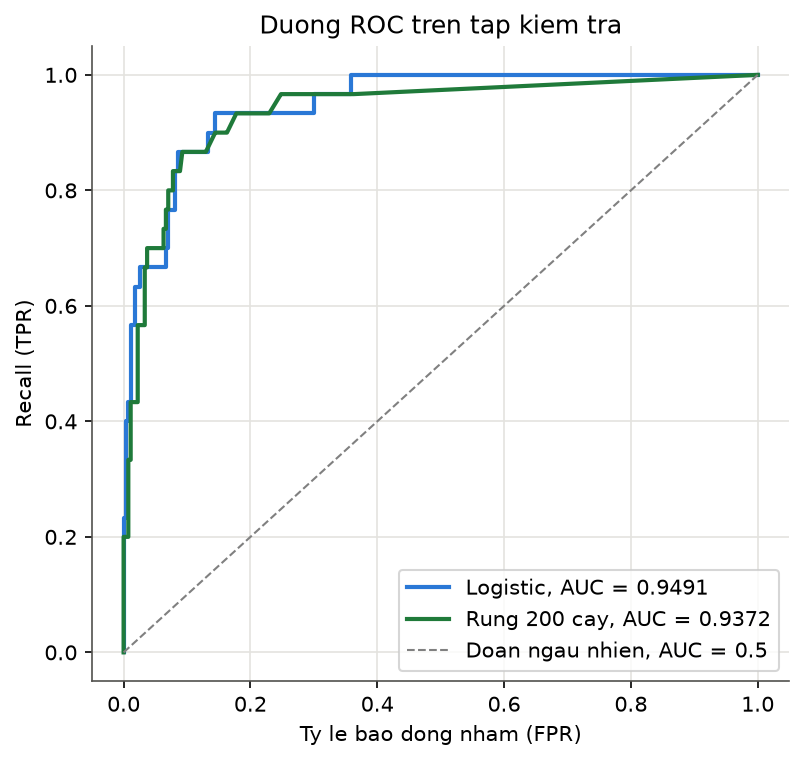

In [18]:
from IPython.display import Image, display
display(Image("roc.png", width=520))

**Nhận xét.** Hồi quy logistic có AUC **0.9491**, rừng 200 cây **0.9372**. Đường của logistic ôm sát góc trên bên trái hơn trên phần lớn trục hoành: trên 2001 điểm chia đều trục báo động nhầm, logistic có recall cao hơn ở 72.6% số điểm, rừng cao hơn ở 9.5%, còn lại bằng nhau. Đường ROC của rừng có 44 điểm, nhiều hơn 36 của logistic, vì xác suất của rừng là tỷ lệ phiếu của 200 cây (bội của 0.005) nên có nhiều mức hoà và bậc thang khác.

**Có, hai đường cắt nhau.** Logistic cao hơn ở đầu đường (báo nhầm 0–0.033), rồi **rừng vượt lên ở đoạn báo nhầm 0.037–0.081** (ứng với khoảng 10–22 bạn báo nhầm), hai đường đi trùng nhau ở vài đoạn, rừng lại nhỉnh hơn ở **0.248–0.299**, và từ 0.36 trở đi logistic cao hơn tới cuối. Nghĩa là AUC cao hơn không có nghĩa là tốt hơn ở **mọi** ngưỡng: nếu nhà trường chỉ chịu được khoảng 5–8% báo nhầm, rừng tìm ra được nhiều bạn hơn một chút. AUC gộp cả đường thành một số, nên khi chọn mô hình cho một vùng ngưỡng cụ thể vẫn phải nhìn đường. Với 30 bạn bỏ học, mỗi bậc của đường cao 0.033, nên các đoạn cắt nhau ở đây chỉ chênh một hai bạn.

## Bài tập 5: Cân bằng lớp cho mô hình khác
Thêm `class_weight="balanced"` cho `RandomForestClassifier` và `SVC`, so precision, recall, F1 trên tập kiểm tra trước và sau. Mô hình nào thay đổi nhiều nhất?

In [19]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, precision_score, recall_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

df = pd.read_csv("data/sinh_vien_bo_hoc.csv")
X = df.drop(columns="bo_hoc")
y = df["bo_hoc"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)


def tao(loai, can_bang):
    """Tao mo hinh, co hoac khong co class_weight='balanced'."""
    cw = "balanced" if can_bang else None
    if loai == "Logistic":
        return make_pipeline(StandardScaler(), LogisticRegression(class_weight=cw))
    if loai == "Rung 200 cay":
        return RandomForestClassifier(200, class_weight=cw, random_state=0)
    return make_pipeline(StandardScaler(), SVC(class_weight=cw, random_state=0))


print("Tap kiem tra (nguong mac dinh cua predict)")
print("Mo hinh        can bang  so bao  precision  recall   F1")
thay_doi = {}
for loai in ["Logistic", "Rung 200 cay", "SVM RBF"]:
    kq = []
    for cb in [False, True]:
        du = tao(loai, cb).fit(X_tr, y_tr).predict(X_te)
        p = precision_score(y_te, du, zero_division=0)
        r = recall_score(y_te, du)
        f = f1_score(y_te, du)
        kq.append((p, r, f))
        print(f"  {loai:13s} {'co ' if cb else 'khong':5s}    {du.sum():4d}"
              f"    {p:.4f}    {r:.4f}  {f:.4f}")
    thay_doi[loai] = [kq[1][i] - kq[0][i] for i in range(3)]
print()

print("Thay doi khi them class_weight='balanced'")
print("Mo hinh        precision  recall    F1")
for loai, (dp, dr, df1) in thay_doi.items():
    print(f"  {loai:13s} {dp:+.4f}   {dr:+.4f}  {df1:+.4f}")

Tap kiem tra (nguong mac dinh cua predict)
Mo hinh        can bang  so bao  precision  recall   F1
  Logistic      khong      20    0.8500    0.5667  0.6800
  Logistic      co         55    0.4727    0.8667  0.6118


  Rung 200 cay  khong      24    0.7083    0.5667  0.6296


  Rung 200 cay  co         31    0.6452    0.6667  0.6557
  SVM RBF       khong      18    0.8333    0.5000  0.6250
  SVM RBF       co         52    0.5192    0.9000  0.6585

Thay doi khi them class_weight='balanced'
Mo hinh        precision  recall    F1
  Logistic      -0.3773   +0.3000  -0.0682
  Rung 200 cay  -0.0632   +0.1000  +0.0261
  SVM RBF       -0.3141   +0.4000  +0.0335


**Nhận xét.** Trước và sau khi thêm `class_weight="balanced"` (ngưỡng mặc định của `predict`):

| Mô hình | Số bạn bị báo | Precision | Recall | F1 |
|---|---|---|---|---|
| Logistic | 20 → 55 | 0.8500 → 0.4727 | 0.5667 → 0.8667 | 0.6800 → 0.6118 |
| Rừng 200 cây | 24 → 31 | 0.7083 → 0.6452 | 0.5667 → 0.6667 | 0.6296 → 0.6557 |
| SVM RBF | 18 → 52 | 0.8333 → 0.5192 | 0.5000 → **0.9000** | 0.6250 → 0.6585 |

**SVM thay đổi nhiều nhất**: recall tăng 0.40 (từ 15 lên 27 trên 30 bạn), số bạn bị báo gần gấp ba. Với SVM, trọng số lớp nhân hằng số phạt C của các bạn bỏ học lên khoảng 9 lần, nên biên bị đẩy hẳn về phía lớp đông. Sau cân bằng, SVM có recall cao nhất và F1 cao nhất trong ba mô hình. Logistic thay đổi tương tự về độ lớn (precision giảm 0.377, recall tăng 0.30) nhưng F1 lại giảm, vì precision mất nhiều hơn recall được.

**Rừng thay đổi ít nhất** (recall chỉ +0.10, thêm 7 lời báo). Mỗi cây trong rừng mọc tự do tới khi lá gần như thuần, nên trọng số lớp chỉ đổi kết luận ở số ít lá còn lẫn lộn; trong lá thuần, nhân trọng số bao nhiêu cũng không đổi lớp đa số. Muốn rừng báo nhiều hơn, hạ ngưỡng trên `predict_proba` (hoặc giới hạn cỡ lá để lá lẫn lộn hơn) hiệu quả hơn.

Không mô hình nào sau cân bằng là "tốt hơn" một cách tuyệt đối: cân bằng lớp chỉ dời điểm đánh đổi, giống hạ ngưỡng ở mục 4.

## Bài tập 6: MAE và RMSE với một lần đoán hỏng
Trên giá nhà của bài 1, tính MAE, RMSE, R² của hồi quy tuyến tính trên tập kiểm tra; cộng thêm 5 tỷ vào dự đoán của đúng một căn rồi tính lại. Con số nào thay đổi nhiều nhất? Vì sao RMSE phạt nặng sai số lớn hơn MAE?

In [20]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

df = pd.read_csv("data/gia_nha.csv")
X = df[["dien_tich"]]
y = df["gia"]

# Cùng cách chia với bài 1
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2,
                                          random_state=42)
duong = LinearRegression().fit(X_tr, y_tr)
du = duong.predict(X_te)


def ba_so(y_that, y_doan):
    mae = mean_absolute_error(y_that, y_doan)
    rmse = np.sqrt(mean_squared_error(y_that, y_doan))
    r2 = r2_score(y_that, y_doan)
    return mae, rmse, r2


# Cộng thêm 5 tỷ vào dự đoán của đúng một căn (căn đầu tiên của tập kiểm tra)
du_hong = du.copy()
du_hong[0] += 5.0
print(f"Tap kiem tra {len(y_te)} can. Can bi doan hong: "
      f"{X_te.iloc[0, 0]} m2, gia that {y_te.iloc[0]:.2f} ty,"
      f" doan {du[0]:.2f} -> {du_hong[0]:.2f} ty")
print()

truoc = ba_so(y_te, du)
sau = ba_so(y_te, du_hong)
print("thuoc do   truoc     sau     tang      gap")
for ten, a, b in zip(["MAE", "RMSE", "R2"], truoc, sau):
    print(f"  {ten:5s}  {a:7.4f}  {b:7.4f}  {b - a:+7.4f}  {b / a:6.2f} lan")
print()

# Vì sao RMSE nhạy hơn: xem sai số của từng căn trước và sau
sai_truoc = np.abs(y_te.to_numpy() - du)
sai_sau = np.abs(y_te.to_numpy() - du_hong)
n = len(y_te)
print(f"Sai so tuyet doi cua can do: {sai_truoc[0]:.4f} -> {sai_sau[0]:.4f}")
print(f"Phan dong gop cua can do vao tong |sai so|: "
      f"{sai_truoc[0] / sai_truoc.sum():.1%} -> {sai_sau[0] / sai_sau.sum():.1%}")
print(f"Phan dong gop cua can do vao tong binh phuong sai so: "
      f"{sai_truoc[0] ** 2 / (sai_truoc ** 2).sum():.1%}"
      f" -> {sai_sau[0] ** 2 / (sai_sau ** 2).sum():.1%}")
print(f"MAE tang dung 5 / {n} = {5 / n:.4f} (neu sai so cung dau)")

Tap kiem tra 12 can. Can bi doan hong: 35.5 m2, gia that 3.00 ty, doan 3.22 -> 8.22 ty

thuoc do   truoc     sau     tang      gap
  MAE     0.2578   0.6745  +0.4167    2.62 lan
  RMSE    0.3730   1.5505  +1.1775    4.16 lan
  R2      0.9622   0.3475  -0.6148    0.36 lan

Sai so tuyet doi cua can do: 0.2179 -> 5.2179
Phan dong gop cua can do vao tong |sai so|: 7.0% -> 64.5%
Phan dong gop cua can do vao tong binh phuong sai so: 2.8% -> 94.4%
MAE tang dung 5 / 12 = 0.4167 (neu sai so cung dau)


**Nhận xét.** Hồi quy tuyến tính trên giá nhà (cùng cách chia bài 1, 12 căn kiểm tra): MAE **0.2578** (khớp con số đường thẳng ở bài 1 và bài 5), RMSE **0.3730**, R² **0.9622**. Cộng 5 tỷ vào dự đoán của căn kiểm tra đầu tiên (35.5 m², giá thật 3.00 tỷ, đoán 3.22 → 8.22 tỷ):

| Thước đo | Trước | Sau | Thay đổi |
|---|---|---|---|
| MAE | 0.2578 | 0.6745 | gấp 2.62 lần (+0.4167) |
| RMSE | 0.3730 | 1.5505 | **gấp 4.16 lần** (+1.1775) |
| R² | 0.9622 | 0.3475 | giảm 0.6148 |

**RMSE thay đổi nhiều nhất** về tỷ lệ (R² cũng sập mạnh, vì R² = 1 − tổng bình phương sai số / tổng bình phương độ lệch của giá, tức cùng gốc bình phương với RMSE). MAE tăng đúng 5 / 12 = 0.4167, vì căn đó vốn bị đoán cao, sai số cùng dấu nên |sai số| tăng đúng 5.

**Vì sao RMSE phạt nặng hơn:** MAE cộng |sai số|, mỗi căn đóng góp theo tỷ lệ bậc nhất; RMSE cộng **bình phương** sai số rồi mới lấy căn. Sai số của căn đó tăng từ 0.22 lên 5.22 (gấp 24 lần), nhưng bình phương tăng từ 0.047 lên 27.2 (gấp 570 lần). Một căn đó chiếm **64.5%** tổng |sai số| nhưng chiếm tới **94.4%** tổng bình phương sai số. Vì vậy RMSE hợp khi một lần đoán hỏng nặng là rất đắt (định giá nhà sai 5 tỷ), còn MAE hợp khi muốn một con số ít bị vài điểm bất thường chi phối. Báo cáo cả hai: RMSE lớn hơn MAE nhiều là dấu hiệu có vài lỗi rất lớn.